# Module 2 — Calibration du modèle GBM (XAU/USD)

Objectif : estimer les deux paramètres du mouvement brownien géométrique
(GBM) — la dérive et la volatilité — à partir de la série de rendements
log préparée dans `01_preprocessing_xau_1d.ipynb`. C'est l'étape qui
transforme l'équation générique `dS_t = μ S_t dt + σ S_t dW_t` en un
modèle concrètement paramétré pour l'or.

Rappel de la méthode (des moments) :
- `ν = μ − σ²/2` : le terme qui apparaît directement dans la trajectoire
  simulée du GBM, estimé par la moyenne des rendements log annualisée.
- `σ` : la volatilité, estimée par l'écart-type des rendements log
  annualisé (`× √252`).
- `μ` (le rendement arithmétique "pur") se retrouve ensuite par
  `μ = ν + σ²/2` — utile pour l'interprétation économique, pas
  strictement nécessaire pour la simulation elle-même.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4.5)

df = pd.read_csv("../data/processed/xau_1d_processed.csv", index_col=0, parse_dates=True)
returns = df["log_return"].dropna()
print(f"Série chargée : {len(df)} lignes, {len(returns)} rendements exploitables (4 neutralisés cross-gap).")

Série chargée : 5531 lignes, 5526 rendements exploitables (4 neutralisés cross-gap).


## 1. Calibration sur l'historique complet (2004-2026)

C'est la calibration de référence ("baseline") : elle utilise tout
l'historique disponible, donc elle intègre à la fois les crises majeures
(2008, 2013) et les régimes plus calmes.

In [2]:
def calibrate_gbm(r: pd.Series, label: str) -> dict:
    """Calibration GBM par la méthode des moments sur une série de rendements log journaliers."""
    daily_mean = r.mean()
    daily_std = r.std()
    nu = daily_mean * 252          # terme de dérive utilisé dans la trajectoire simulée
    sigma = daily_std * np.sqrt(252)  # volatilité annualisée
    mu = nu + sigma**2 / 2          # rendement arithmétique annualisé "pur"
    return {
        "label": label, "n_obs": len(r),
        "daily_mean": daily_mean, "daily_std": daily_std,
        "nu_annual": nu, "sigma_annual": sigma, "mu_annual": mu,
    }


full = calibrate_gbm(returns, "Historique complet (2004-2026)")
pd.Series(full)

label           Historique complet (2004-2026)
n_obs                                     5526
daily_mean                            0.000415
daily_std                             0.010906
nu_annual                             0.104542
sigma_annual                          0.173126
mu_annual                             0.119528
dtype: object

**Interprétation** — sur 5526 observations, on obtient σ ≈ **17,31%** et
ν ≈ **10,45%** (soit μ ≈ **11,95%** en rendement arithmétique pur). Ces
deux chiffres — σ et ν — sont littéralement tout ce dont le moteur Monte
Carlo aura besoin pour simuler des trajectoires futures plausibles de
l'or : à chaque pas de temps, une trajectoire simulée appliquera
`S_{t+1} = S_t × exp(ν·Δt + σ·√Δt·Z)` avec `Z` un tirage aléatoire
normal — donc toute la "personnalité" de l'or dans le modèle tient dans
ces deux nombres.

Un chiffre pour se donner une intuition concrète de σ = 17,31% :
statistiquement, si le GBM était le vrai modèle du marché, on s'attendrait
à ce que le prix de l'or finisse, dans 68% des cas (±1 écart-type), entre
environ -17% et +17% de sa valeur de départ au bout d'un an — et dans 95%
des cas (±2 écarts-types) entre environ -35% et +35%. On verra en section
4 que la réalité a des queues bien plus épaisses que ça.

## 2. Volatilité glissante — le régime change-t-il dans le temps ?

La calibration ci-dessus suppose implicitement que σ est constant sur 21
ans. Avant d'accepter cette hypothèse, on regarde comment la volatilité
a évolué dans le temps avec une fenêtre glissante de 60 jours.

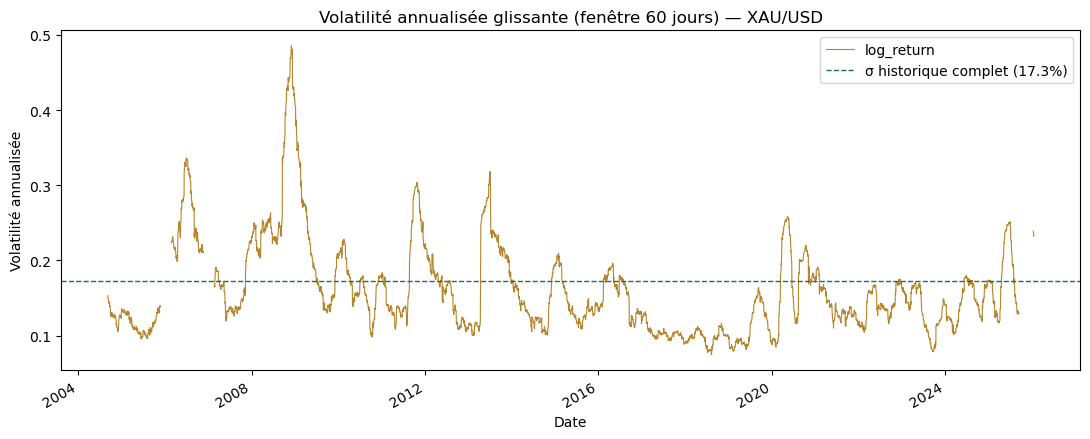

count    5284.000000
mean        0.160008
std         0.061050
min         0.074866
25%         0.118072
50%         0.142358
75%         0.182768
max         0.485494
Name: log_return, dtype: float64


In [3]:
rolling_vol = df["log_return"].rolling(60).std() * np.sqrt(252)

fig, ax = plt.subplots()
rolling_vol.plot(ax=ax, color="#b5862c", linewidth=0.8)
ax.axhline(full["sigma_annual"], color="#1f6f54", linestyle="--", linewidth=1, label=f"σ historique complet ({full['sigma_annual']:.1%})")
ax.set_title("Volatilité annualisée glissante (fenêtre 60 jours) — XAU/USD")
ax.set_ylabel("Volatilité annualisée")
ax.legend()
plt.tight_layout()
plt.show()

print(rolling_vol.describe())

**Interprétation** — la volatilité glissante oscille entre ~7,5% (périodes
calmes) et un pic à ~48,5% (bien au-dessus de la moyenne de 16%), et elle
ne reste jamais plate longtemps : c'est la confirmation directe du
clustering de volatilité déjà repéré visuellement dans le notebook 1. Les
pics les plus nets correspondent aux périodes déjà identifiées comme
extrêmes (crise 2008, krach 2013, et la fin de série 2025-2026).

Conséquence méthodologique importante : **l'hypothèse GBM d'une
volatilité constante dans le temps est une simplification qu'on sait déjà
fausse** au vu de ce graphique — le vrai comportement de l'or est plus
proche d'un modèle à volatilité stochastique (type Heston) ou à régimes
changeants. On garde le GBM pour ce module parce que c'est le modèle de
référence pédagogique et le plus simple à calibrer/expliquer/justifier
(cohérent avec le périmètre du module), mais cette limite doit être
explicitement mentionnée dans le rapport — ce n'est pas un oubli, c'est un
choix de scope assumé.

## 3. Sensibilité à la fenêtre de calibration

Question laissée ouverte précédemment : calibrer sur les 21 ans complets,
ou sur une fenêtre plus récente ? On compare 3 fenêtres.

In [4]:
last_date = df.index.max()
r_10y = df.loc[last_date - pd.DateOffset(years=10):, "log_return"].dropna()
r_5y = df.loc[last_date - pd.DateOffset(years=5):, "log_return"].dropna()

c10 = calibrate_gbm(r_10y, "10 dernières années")
c5 = calibrate_gbm(r_5y, "5 dernières années")

comparison = pd.DataFrame([full, c10, c5]).set_index("label")[["n_obs", "nu_annual", "sigma_annual", "mu_annual"]]
comparison.columns = ["n observations", "ν (dérive sim.)", "σ (volatilité)", "μ (rendement pur)"]
comparison.style.format({"ν (dérive sim.)": "{:.2%}", "σ (volatilité)": "{:.2%}", "μ (rendement pur)": "{:.2%}"})

,n observations,ν (dérive sim.),σ (volatilité),μ (rendement pur)
label,,,,
Historique complet (2004-2026),5526,10.45%,17.31%,11.95%
10 dernières années,2551,12.42%,14.86%,13.53%
5 dernières années,1261,15.09%,15.95%,16.36%


**Interprétation** — les trois fenêtres donnent des paramètres nettement
différents :

| Fenêtre | σ | ν | μ |
|---|---|---|---|
| 21 ans complets | 17,31% | 10,45% | 11,95% |
| 10 dernières années | 14,86% | 12,42% | 13,53% |
| 5 dernières années | 15,95% | 15,09% | 16,36% |

La fenêtre complète a la volatilité la plus élevée (elle inclut 2008 et
2013, les deux chocs les plus violents de toute la série) mais la dérive
la plus faible. À l'inverse, la fenêtre des 5 dernières années montre une
dérive bien plus forte (15,09% contre 10,45%) — cohérent avec le fort
rallye de l'or en 2025-2026 déjà identifié — pour une volatilité
intermédiaire.

Le compromis est classique en calibration de modèle de marché : une
fenêtre longue est plus robuste statistiquement (plus d'observations,
moins sensible au bruit d'échantillonnage) mais peut mal représenter le
régime *actuel* si le marché a structurellement changé de comportement ;
une fenêtre courte colle mieux au régime récent mais généralise moins
bien et serait plus sensible à un futur retournement.

**Choix retenu pour la suite du pipeline** : la calibration sur
l'historique complet (21 ans) comme référence pour la simulation Monte
Carlo et le calcul de la VaR "normale", parce qu'elle inclut des épisodes
de stress réels (2008, 2013) que le modèle doit être capable de refléter
— c'est justement la logique de la VaR. La calibration sur 5 ans sera
réutilisée séparément pour la **VaR stressée** (recalibration sur une
fenêtre récente/de crise, cf. périmètre du module), où c'est le régime
actuel qui doit primer. Ce choix est documenté ici explicitement et reste
révisable.

## 4. Le GBM suppose la normalité — à quel point c'est faux ici ?

Le GBM suppose que les rendements log suivent une loi normale
`N(daily_mean, daily_std²)`. On compare la distribution réelle des
rendements à la courbe normale théorique calibrée sur les mêmes moyenne
et écart-type.

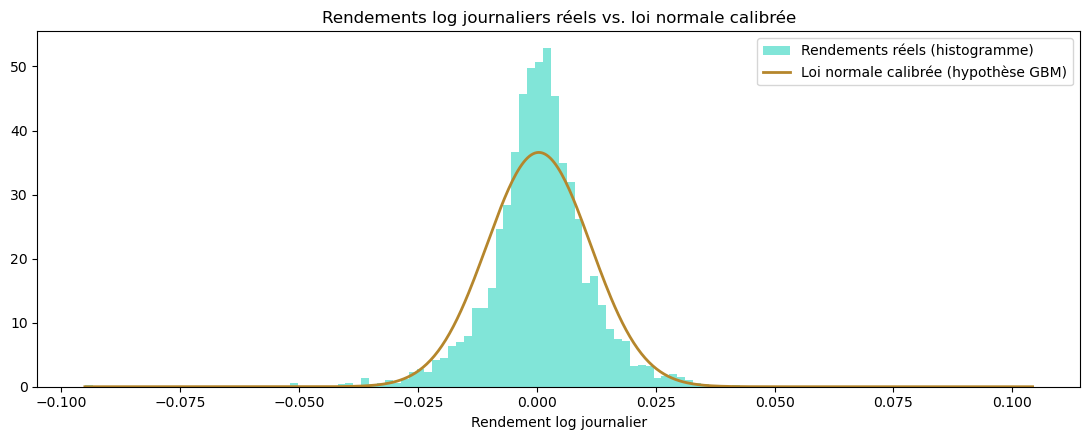

In [5]:
fig, ax = plt.subplots()
ax.hist(returns, bins=120, density=True, alpha=0.6, color="#2dd4bf", label="Rendements réels (histogramme)")

x = np.linspace(returns.min(), returns.max(), 500)
ax.plot(x, stats.norm.pdf(x, loc=full["daily_mean"], scale=full["daily_std"]), color="#b5862c", linewidth=2, label="Loi normale calibrée (hypothèse GBM)")
ax.set_title("Rendements log journaliers réels vs. loi normale calibrée")
ax.set_xlabel("Rendement log journalier")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
threshold = 0.05
empirical_p = (returns.abs() > threshold).mean()
theoretical_p = 2 * (1 - stats.norm.cdf(threshold, loc=full["daily_mean"], scale=full["daily_std"]))

print(f"Probabilité empirique d'un mouvement journalier > 5% (dans un sens ou l'autre) : {empirical_p:.4%} ({(returns.abs() > threshold).sum()} jours sur {len(returns)})")
print(f"Probabilité théorique sous l'hypothèse normale du GBM               : {theoretical_p:.6%}")
print(f"Ratio empirique / théorique : x{empirical_p / theoretical_p:.0f}")

Probabilité empirique d'un mouvement journalier > 5% (dans un sens ou l'autre) : 0.2895% (16 jours sur 5526)
Probabilité théorique sous l'hypothèse normale du GBM               : 0.000545%
Ratio empirique / théorique : x531


**Interprétation** — le graphique montre un histogramme réel nettement
plus "pointu" au centre et avec des bords qui restent visibles bien plus
loin que la courbe normale (les fameuses "queues épaisses"). Le chiffre
le rend indiscutable : un mouvement journalier de plus de 5% dans un sens
ou l'autre est arrivé **16 fois** sur 5526 jours dans la réalité
(0,29%), alors que le GBM calibré prédit que ça devrait arriver environ
**531 fois moins souvent** (0,0005%, soit statistiquement presque
"jamais" sur un échantillon de cette taille).

C'est la démonstration chiffrée, et pas juste théorique, de la limite du
GBM déjà annoncée dans le notebook 1 : **un GBM calibré de cette façon va
mécaniquement sous-estimer la probabilité des mouvements extrêmes de
l'or**. Pour le module, ça a une conséquence directe et utile : c'est
precisément pour ça que la VaR ne doit pas s'appuyer uniquement sur la
méthode "paramétrique" (qui hérite de cette hypothèse de normalité), et
que les méthodes historique et Monte Carlo (qui peuvent capturer des
distributions non-normales si on les configure pour) seront comparées
dans le backtesting de Kupiec — avec l'hypothèse, à vérifier
empiriquement, que la méthode paramétrique sera celle qui échoue le plus
souvent le test de Kupiec sur les épisodes de stress.

## 5. Sauvegarde des paramètres calibrés

In [7]:
import json

gbm_params = {
    "full_history": {k: v for k, v in full.items() if k != "label"},
    "last_10y": {k: v for k, v in c10.items() if k != "label"},
    "last_5y": {k: v for k, v in c5.items() if k != "label"},
    "chosen_baseline": "full_history",
    "chosen_for_var_stressee": "last_5y",
    "note": "ν et σ en termes annualisés ; ν = terme de derive pour la simulation (mu - sigma^2/2), mu = rendement arithmetique pur.",
}

with open("../data/processed/gbm_params.json", "w") as f:
    json.dump(gbm_params, f, indent=2, default=float)

print("Paramètres sauvegardés dans data/processed/gbm_params.json")
json.dumps(gbm_params, indent=2, default=float)

Paramètres sauvegardés dans data/processed/gbm_params.json


'{\n  "full_history": {\n    "n_obs": 5526,\n    "daily_mean": 0.00041484781217830175,\n    "daily_std": 0.01090592675006945,\n    "nu_annual": 0.10454164866893204,\n    "sigma_annual": 0.17312621998422384,\n    "mu_annual": 0.11952799269194497\n  },\n  "last_10y": {\n    "n_obs": 2551,\n    "daily_mean": 0.0004929319353705021,\n    "daily_std": 0.009358885675640749,\n    "nu_annual": 0.12421884771336654,\n    "sigma_annual": 0.14856770427858076,\n    "mu_annual": 0.13525502909067044\n  },\n  "last_5y": {\n    "n_obs": 1261,\n    "daily_mean": 0.0005988260984508308,\n    "daily_std": 0.01004823822842505,\n    "nu_annual": 0.15090417680960938,\n    "sigma_annual": 0.1595108368004695,\n    "mu_annual": 0.16362603033800238\n  },\n  "chosen_baseline": "full_history",\n  "chosen_for_var_stressee": "last_5y",\n  "note": "\\u03bd et \\u03c3 en termes annualis\\u00e9s ; \\u03bd = terme de derive pour la simulation (mu - sigma^2/2), mu = rendement arithmetique pur."\n}'

## 6. Résumé & prochaine étape

- GBM calibré par méthode des moments sur 3 fenêtres : historique complet
  (σ=17,31%, ν=10,45%), 10 ans (σ=14,86%, ν=12,42%), 5 ans (σ=15,95%,
  ν=15,09%).
- Volatilité glissante confirme un comportement non stationnaire
  (clustering) — limite connue et assumée du GBM pour ce module.
- Choix documenté : historique complet comme calibration de référence
  (Monte Carlo + VaR normale), 5 ans réservé à la VaR stressée.
- Écart quantifié entre distribution réelle et hypothèse de normalité du
  GBM (×531 sur la fréquence des mouvements >5%) — limite à mentionner
  explicitement dans le rapport, et hypothèse de travail pour la
  comparaison des 3 méthodes de VaR.

**Prochaine étape** : moteur de simulation Monte Carlo (`src/models/`) —
génération de trajectoires futures de l'or à partir des paramètres
calibrés ici, puis calcul de la VaR (3 méthodes) et de l'Expected
Shortfall sur ces trajectoires.